# EDA orientado a *feature engineering* · Alerta temprana de Dinophysis

Continúa el notebook `fitoplancton.ipynb`. Usa la misma partición temporal
(train 1997–2010, validación 2011–2013, test 2014–2016) y **mira solo train**.

Pregunta que guía este EDA: ¿qué variables nuevas conviene construir y cuáles
descartar antes de modelar la alerta (Dinophysis total ≥ 100 células/L)?

Salidas:
- `salidas_eda/figuras/` → cada figura en PNG (300 dpi) y PDF
- `salidas_eda/tablas/`  → tablas en CSV
- `salidas_eda/resumen_numeros.json` → cifras clave para el reporte

In [1]:
# ============================================================
# 0. CONFIGURACIÓN
# ============================================================
import os
import json
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import roc_auc_score
from sklearn.feature_selection import mutual_info_classif
from scipy.stats import skew, yeojohnson

# Ruta del CSV (se puede cambiar con la variable de entorno RUTA_CSV)
RUTA_CSV = os.environ.get("RUTA_CSV", "Hind_97_16_HAB_weekly_mean.csv")

UMBRAL = 100              # células/L → alerta
CARPETA = "salidas_eda"
CARPETA_FIG = os.path.join(CARPETA, "figuras")
CARPETA_TAB = os.path.join(CARPETA, "tablas")
os.makedirs(CARPETA_FIG, exist_ok=True)
os.makedirs(CARPETA_TAB, exist_ok=True)

# Colores (paleta validada para daltonismo)
AZUL = "#2a78d6"          # sin alerta / serie única
NARANJO = "#eb6834"       # alerta
AQUA = "#1baf7a"          # tercera categoría
GRIS = "#8a8984"
TINTA = "#0b0b0b"
TINTA_2 = "#52514e"

# Mapas de color
CMAP_SEQ = LinearSegmentedColormap.from_list(
    "azul", ["#f4f8fd", "#9ec5f4", "#3987e5", "#1c5cab", "#0d366b"])
CMAP_DIV = LinearSegmentedColormap.from_list(
    "div", ["#104281", "#3987e5", "#f0efec", "#e34948", "#8f2323"])

# Estilo general: etiquetas en negrita, texto de ejes horizontal, grilla tenue
plt.rcParams.update({
    "figure.dpi": 100,
    "savefig.dpi": 300,
    "font.size": 10,
    "axes.titleweight": "bold",
    "axes.labelweight": "bold",
    "axes.titlesize": 11,
    "axes.edgecolor": "#c3c2b7",
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "grid.linewidth": 0.6,
    "axes.axisbelow": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": False,
    "xtick.color": TINTA_2,
    "ytick.color": TINTA_2,
})

# Trazo blanco para que los textos sobre gráficos se lean siempre
BORDE = [pe.withStroke(linewidth=3, foreground="white")]

MESES = ["Ene", "Feb", "Mar", "Abr", "May", "Jun",
         "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]


def guardar(fig, nombre):
    """Guarda la figura como PNG (300 dpi) y PDF."""
    fig.savefig(os.path.join(CARPETA_FIG, nombre + ".png"), dpi=300, bbox_inches="tight")
    fig.savefig(os.path.join(CARPETA_FIG, nombre + ".pdf"), bbox_inches="tight")
    plt.show()
    plt.close(fig)


def auc_univariada(x, y):
    """AUC de una sola variable. >0,5: valores altos van con alerta; <0,5: valores bajos."""
    m = x.notna() & y.notna()
    if m.sum() < 30 or y[m].nunique() < 2:
        return np.nan
    return roc_auc_score(y[m].astype(int), x[m])


NUMEROS = {}   # aquí se guardan las cifras clave para el reporte

In [2]:
# ============================================================
# 1. CARGA, ORDEN Y PARTICIÓN TEMPORAL (igual que el notebook)
# ============================================================
df = pd.read_csv(RUTA_CSV, parse_dates=["time"])
df = df.sort_values(["ID", "time"]).reset_index(drop=True)

df["año"] = df["time"].dt.year
df["mes"] = df["time"].dt.month
df["semana"] = df["time"].dt.isocalendar().week.astype(int)
df["alerta"] = np.where(df["D_total"].notna(), (df["D_total"] >= UMBRAL).astype(float), np.nan)

fisicas = ["sur_temp", "bot_temp", "sur_salt", "bot_salt", "PED", "MLD"]

es_train = df["año"] <= 2010
train = df[es_train].copy()                       # todas las semanas de train
train_dino = train[train["D_total"].notna()].copy()  # semanas con conteo (tienen objetivo)

print("Filas totales:", len(df))
print("Filas train:", len(train), "| con Dinophysis:", len(train_dino))
NUMEROS["filas_total"] = int(len(df))
NUMEROS["filas_train"] = int(len(train))
NUMEROS["filas_train_dino"] = int(len(train_dino))
NUMEROS["n_estaciones"] = int(df["ID"].nunique())
NUMEROS["n_bahias"] = int(df["Group"].nunique())

Filas totales: 32333
Filas train: 22630 | con Dinophysis: 1872


## A. Calidad y estructura de los datos

% de faltantes por bahía (train, todas las semanas):
                 sur_temp  bot_temp  sur_salt  bot_salt  PED    MLD
Group                                                              
Bantry Bay            0.0       0.0       0.0       0.0  0.0    0.0
Celtic Sea            0.0       0.0       0.0       0.0  0.0    0.0
Dingle Bay            0.0       0.0       0.0       0.0  0.0    0.0
Dunmanus Bay          0.0       0.0       0.0       0.0  0.0    0.0
Kenmare Bay           0.0       0.0       0.0       0.0  0.0    0.0
Long Island Bay       0.0       0.0       0.0       0.0  0.0    0.0
Tralee Bay          100.0     100.0     100.0     100.0  0.0  100.0

Bahías de las filas sin temperatura: {'Tralee Bay': 1043}
PED en esas filas: {'count': 1043.0, 'mean': 0.0, 'std': 0.0, 'min': 0.0, '25%': 0.0, '50%': 0.0, '75%': 0.0, 'max': 0.0}
Filas con PED = 0 de relleno (se pasan a NaN): 1043


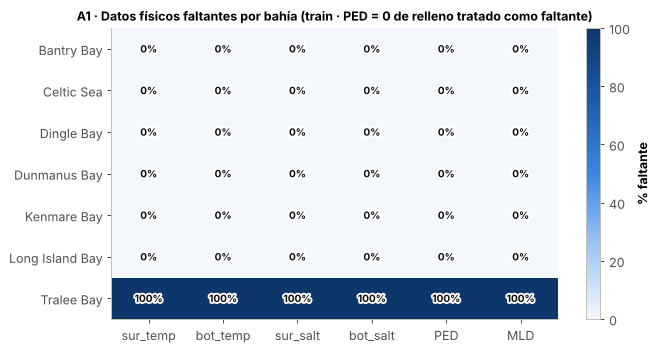

In [3]:
# ------------------------------------------------------------
# A1. ¿Dónde faltan las variables físicas?
# ------------------------------------------------------------
falt_bahia = train.groupby("Group")[fisicas].apply(lambda d: d.isna().mean() * 100).round(1)
print("% de faltantes por bahía (train, todas las semanas):")
print(falt_bahia)
falt_bahia.to_csv(os.path.join(CARPETA_TAB, "A1_faltantes_por_bahia.csv"))

# ¿Las filas sin física son siempre las mismas? ¿Qué pasa con PED ahí?
sin_fisica = df[df["sur_temp"].isna()]
print("\nBahías de las filas sin temperatura:", sin_fisica["Group"].value_counts().to_dict())
print("PED en esas filas:", sin_fisica["PED"].describe().round(2).to_dict())
NUMEROS["bahias_sin_fisica"] = sin_fisica["Group"].value_counts().to_dict()
NUMEROS["PED_en_filas_sin_fisica"] = sin_fisica["PED"].describe().round(3).to_dict()
NUMEROS["train_dino_sin_fisica"] = int(train_dino["sur_temp"].isna().sum())

# CORRECCIÓN: en las filas sin física (Tralee Bay) PED vale siempre 0.
# Un 0 constante no es un dato real (sería una columna sin estratificación nunca):
# es un relleno. Se marca como faltante para que no engañe al modelo.
n_ped_falso = int((df["sur_temp"].isna() & (df["PED"] == 0)).sum())
print("Filas con PED = 0 de relleno (se pasan a NaN):", n_ped_falso)
NUMEROS["n_PED_relleno"] = n_ped_falso
df.loc[df["sur_temp"].isna(), "PED"] = np.nan
train = df[df["año"] <= 2010].copy()
train_dino = train[train["D_total"].notna()].copy()
falt_bahia = train.groupby("Group")[fisicas].apply(lambda d: d.isna().mean() * 100).round(1)

fig, ax = plt.subplots(figsize=(8, 4.2))
im = ax.imshow(falt_bahia.values, cmap=CMAP_SEQ, vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(fisicas)))
ax.set_xticklabels(fisicas, rotation=0)
ax.set_yticks(range(len(falt_bahia)))
ax.set_yticklabels(falt_bahia.index)
ax.grid(False)
for i in range(falt_bahia.shape[0]):
    for j in range(falt_bahia.shape[1]):
        ax.text(j, i, f"{falt_bahia.iat[i, j]:.0f}%", ha="center", va="center",
                fontsize=8, fontweight="bold", color=TINTA, path_effects=BORDE)
plt.colorbar(im, ax=ax, label="% faltante")
ax.set_title("A1 · Datos físicos faltantes por bahía (train · PED = 0 de relleno tratado como faltante)",
             fontsize=10)
guardar(fig, "A1_faltantes_por_bahia")

In [4]:
# ------------------------------------------------------------
# A2. Revisiones rápidas: signo de MLD y semana 53
# ------------------------------------------------------------
print("MLD: mínimo", round(df["MLD"].min(), 2), "| máximo", round(df["MLD"].max(), 2))
print("MLD > 0:", int((df["MLD"] > 0).sum()), "filas")
print("Filas con semana ISO 53:", int((df["semana"] == 53).sum()))
NUMEROS["MLD_min"] = float(round(df["MLD"].min(), 2))
NUMEROS["MLD_max"] = float(round(df["MLD"].max(), 2))
NUMEROS["MLD_positivos"] = int((df["MLD"] > 0).sum())
NUMEROS["filas_semana53"] = int((df["semana"] == 53).sum())

MLD: mínimo -48.75 | máximo -0.97
MLD > 0: 0 filas
Filas con semana ISO 53: 124


        n   tasa  sur_temp_media
año                             
1997  182  0.005          12.046
1998  119  0.059          11.828
1999  101  0.000          11.733
2000  141  0.050          11.415
2001  215  0.144          11.456
2002  168  0.065          11.903
2003  113  0.204          12.296
2004  181  0.276          11.644
2005  154  0.240          11.812
2006   66  0.106          11.957
2007   30  0.100          12.109
2008  102  0.137          11.503
2009  128  0.266          11.430
2010  172  0.291          11.116


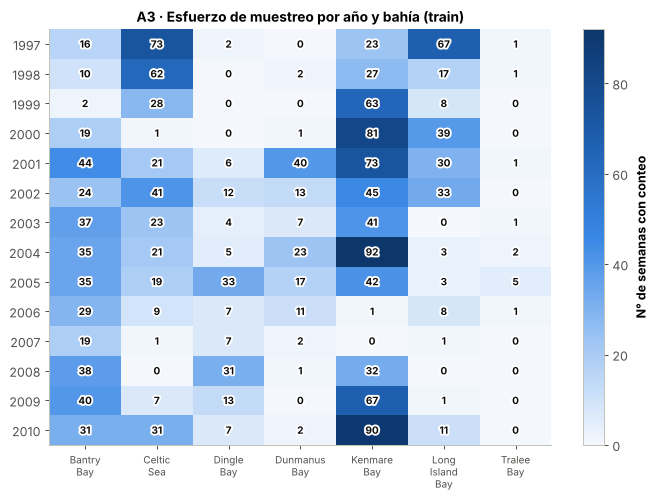

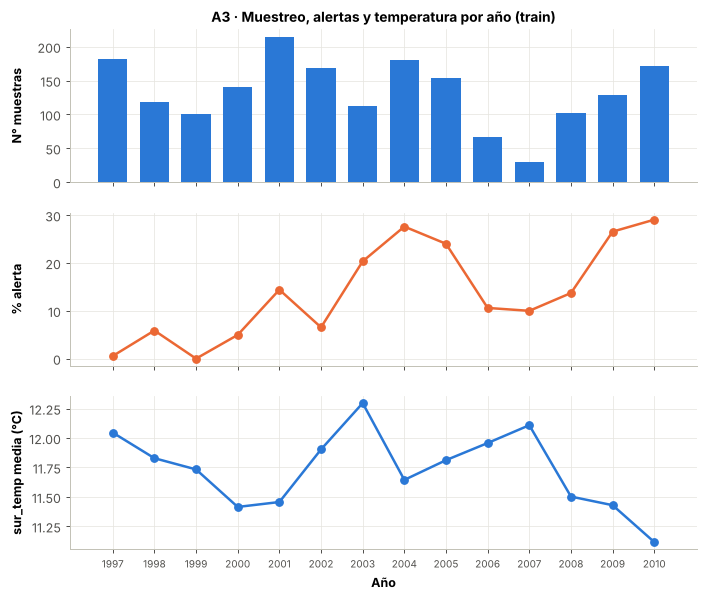

In [5]:
# ------------------------------------------------------------
# A3. Esfuerzo de muestreo y deriva temporal dentro de train
# ------------------------------------------------------------
esfuerzo = pd.crosstab(train_dino["año"], train_dino["Group"])
esfuerzo.to_csv(os.path.join(CARPETA_TAB, "A3_muestras_por_año_bahia.csv"))

por_año = train_dino.groupby("año").agg(n=("alerta", "size"), tasa=("alerta", "mean"))
temp_año = train.groupby("año")["sur_temp"].mean()
por_año["sur_temp_media"] = temp_año
por_año.to_csv(os.path.join(CARPETA_TAB, "A3_alerta_por_año.csv"))
print(por_año.round(3))
NUMEROS["muestras_por_año_min"] = int(por_año["n"].min())
NUMEROS["muestras_por_año_max"] = int(por_año["n"].max())
NUMEROS["año_menos_muestras"] = int(por_año["n"].idxmin())
NUMEROS["tasa_alerta_año_min"] = float(round(por_año["tasa"].min() * 100, 1))
NUMEROS["tasa_alerta_año_max"] = float(round(por_año["tasa"].max() * 100, 1))
NUMEROS["corr_n_vs_tasa_spearman"] = float(round(por_año["n"].corr(por_año["tasa"], method="spearman"), 2))

# Mapa de calor año × bahía
fig, ax = plt.subplots(figsize=(9, 6))
im = ax.imshow(esfuerzo.values, cmap=CMAP_SEQ, aspect="auto")
ax.set_xticks(range(esfuerzo.shape[1]))
ax.set_xticklabels([g.replace(" ", "\n") for g in esfuerzo.columns], rotation=0, fontsize=8)
ax.set_yticks(range(esfuerzo.shape[0]))
ax.set_yticklabels(esfuerzo.index)
ax.grid(False)
for i in range(esfuerzo.shape[0]):
    for j in range(esfuerzo.shape[1]):
        ax.text(j, i, esfuerzo.iat[i, j], ha="center", va="center", fontsize=8,
                fontweight="bold", color=TINTA, path_effects=BORDE)
plt.colorbar(im, ax=ax, label="N° de semanas con conteo")
ax.set_title("A3 · Esfuerzo de muestreo por año y bahía (train)")
guardar(fig, "A3a_esfuerzo_muestreo")

# Tres paneles apilados (en vez de doble eje)
fig, axes = plt.subplots(3, 1, figsize=(9, 7.5), sharex=True)
axes[0].bar(por_año.index, por_año["n"], color=AZUL, width=0.7)
axes[0].set_ylabel("N° muestras")
axes[0].set_title("A3 · Muestreo, alertas y temperatura por año (train)")
axes[1].plot(por_año.index, por_año["tasa"] * 100, color=NARANJO, lw=2, marker="o", ms=6)
axes[1].set_ylabel("% alerta")
axes[2].plot(por_año.index, por_año["sur_temp_media"], color=AZUL, lw=2, marker="o", ms=6)
axes[2].set_ylabel("sur_temp media (°C)")
axes[2].set_xlabel("Año")
axes[2].set_xticks(por_año.index)
axes[2].tick_params(axis="x", rotation=0, labelsize=8)
fig.align_ylabels(axes)
guardar(fig, "A3b_deriva_por_año")

## B. Variable objetivo

% semanas con cero células: 72.4%
% semanas en alerta (≥100): 14.7%


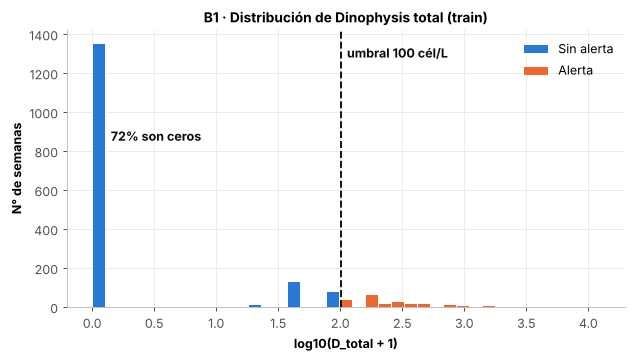

In [6]:
# ------------------------------------------------------------
# B1. Distribución de Dinophysis total y lugar del umbral
# ------------------------------------------------------------
y = train_dino["alerta"]
pct_ceros = (train_dino["D_total"] == 0).mean() * 100
pct_alerta = y.mean() * 100
print(f"% semanas con cero células: {pct_ceros:.1f}%")
print(f"% semanas en alerta (≥{UMBRAL}): {pct_alerta:.1f}%")
NUMEROS["pct_ceros"] = float(round(pct_ceros, 1))
NUMEROS["pct_alerta_train"] = float(round(pct_alerta, 1))
NUMEROS["n_alerta_train"] = int(y.sum())
NUMEROS["D_total_max"] = float(train_dino["D_total"].max())
NUMEROS["D_total_mediana_alerta"] = float(train_dino.loc[y == 1, "D_total"].median())

fig, ax = plt.subplots(figsize=(8, 4))
x_log = np.log10(train_dino["D_total"] + 1)
bins = np.linspace(0, x_log.max() + 0.1, 40)
ax.hist(x_log[y == 0], bins=bins, color=AZUL, label="Sin alerta", edgecolor="white", linewidth=0.8)
ax.hist(x_log[y == 1], bins=bins, color=NARANJO, label="Alerta", edgecolor="white", linewidth=0.8)
ax.axvline(np.log10(UMBRAL + 1), color=TINTA, lw=1.5, ls="--")
ax.text(np.log10(UMBRAL + 1) + 0.05, ax.get_ylim()[1] * 0.9, f"umbral {UMBRAL} cél/L",
        fontweight="bold", color=TINTA, path_effects=BORDE)
ax.text(0.15, ax.get_ylim()[1] * 0.6, f"{pct_ceros:.0f}% son ceros", fontweight="bold",
        color=TINTA, path_effects=BORDE)
ax.set_xlabel("log10(D_total + 1)")
ax.set_ylabel("N° de semanas")
ax.set_title("B1 · Distribución de Dinophysis total (train)")
ax.legend()
guardar(fig, "B1_distribucion_objetivo")

   umbral_cel_L  pct_alerta  n_alerta
0             1        27.6       517
1            50        19.4       363
2           100        14.7       275
3           200        10.3       193
4           500         4.2        78
5          1000         2.6        49


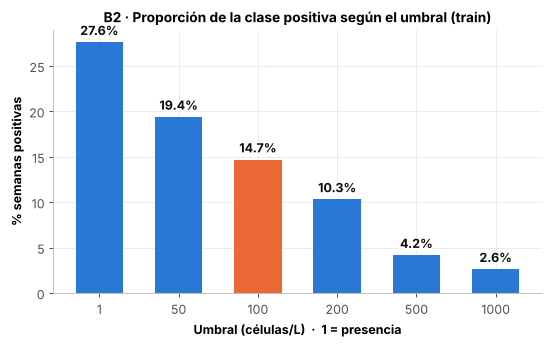

In [7]:
# ------------------------------------------------------------
# B2. Sensibilidad al umbral: ¿cuántas alertas habría con otro corte?
# ------------------------------------------------------------
umbrales = [1, 50, 100, 200, 500, 1000]
prev = []
for u in umbrales:
    prev.append((train_dino["D_total"] >= u).mean() * 100)
tabla_umbral = pd.DataFrame({"umbral_cel_L": umbrales, "pct_alerta": np.round(prev, 1),
                             "n_alerta": [int((train_dino["D_total"] >= u).sum()) for u in umbrales]})
tabla_umbral.to_csv(os.path.join(CARPETA_TAB, "B2_sensibilidad_umbral.csv"), index=False)
print(tabla_umbral)
NUMEROS["tabla_umbral"] = tabla_umbral.to_dict(orient="records")

fig, ax = plt.subplots(figsize=(7, 3.8))
colores_b = [NARANJO if u == UMBRAL else AZUL for u in umbrales]
ax.bar([str(u) for u in umbrales], prev, color=colores_b, width=0.6)
for i, p in enumerate(prev):
    ax.text(i, p + 0.8, f"{p:.1f}%", ha="center", fontweight="bold", color=TINTA, path_effects=BORDE)
ax.set_xlabel("Umbral (células/L)  ·  1 = presencia")
ax.set_ylabel("% semanas positivas")
ax.set_title("B2 · Proporción de la clase positiva según el umbral (train)")
guardar(fig, "B2_sensibilidad_umbral")

## C. Variables físicas originales

   variable  skew_original  skew_log1p  skew_yeojohnson
0  sur_temp           0.14       -0.26            -0.04
1  bot_temp           0.42       -0.10            -0.00
2  sur_salt          -3.61       -3.89            -0.13
3  bot_salt          -1.34       -1.39            -0.07
4       PED           2.12        0.43             0.07
5       MLD          -0.78         NaN            -0.29


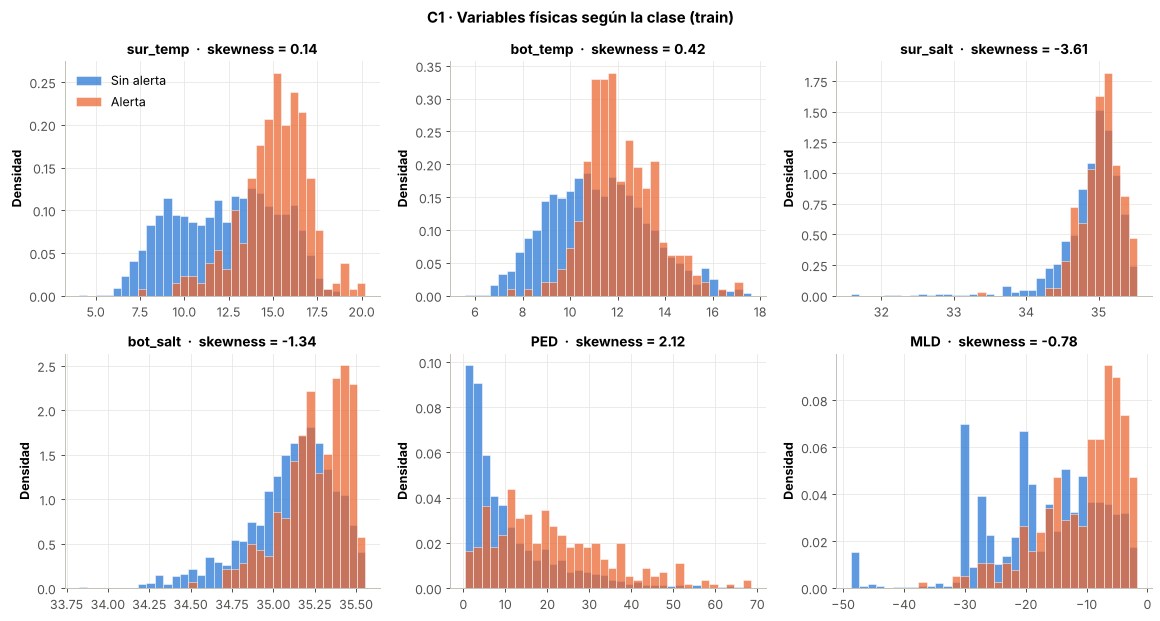

In [8]:
# ------------------------------------------------------------
# C1. Distribución por clase y asimetría (skewness)
# ------------------------------------------------------------
asim = []
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, v in zip(axes.ravel(), fisicas):
    datos = train_dino[[v, "alerta"]].dropna()
    b = np.linspace(datos[v].min(), datos[v].max(), 35)
    ax.hist(datos.loc[datos["alerta"] == 0, v], bins=b, density=True, color=AZUL,
            alpha=0.75, label="Sin alerta", edgecolor="white", linewidth=0.5)
    ax.hist(datos.loc[datos["alerta"] == 1, v], bins=b, density=True, color=NARANJO,
            alpha=0.75, label="Alerta", edgecolor="white", linewidth=0.5)
    s = skew(train[v].dropna())
    ax.set_title(f"{v}  ·  skewness = {s:.2f}")
    ax.set_ylabel("Densidad")
    # asimetría con transformaciones
    x_all = train[v].dropna()
    s_yj = skew(yeojohnson(x_all - x_all.min() if v == "MLD" else x_all)[0])
    s_log = skew(np.log1p(x_all)) if x_all.min() >= 0 else np.nan
    asim.append({"variable": v, "skew_original": round(s, 2),
                 "skew_log1p": round(s_log, 2) if not np.isnan(s_log) else None,
                 "skew_yeojohnson": round(s_yj, 2)})
axes[0, 0].legend()
fig.suptitle("C1 · Variables físicas según la clase (train)", fontweight="bold")
fig.tight_layout()
guardar(fig, "C1_distribuciones_por_clase")

tabla_asim = pd.DataFrame(asim)
tabla_asim.to_csv(os.path.join(CARPETA_TAB, "C1_asimetria.csv"), index=False)
print(tabla_asim)
NUMEROS["asimetria"] = tabla_asim.to_dict(orient="records")

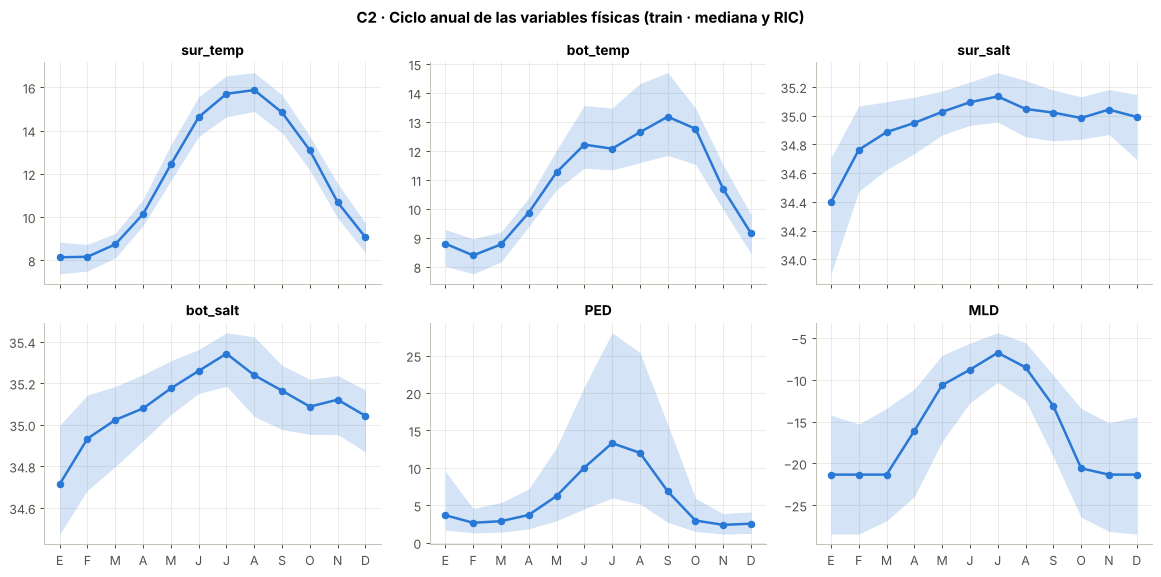

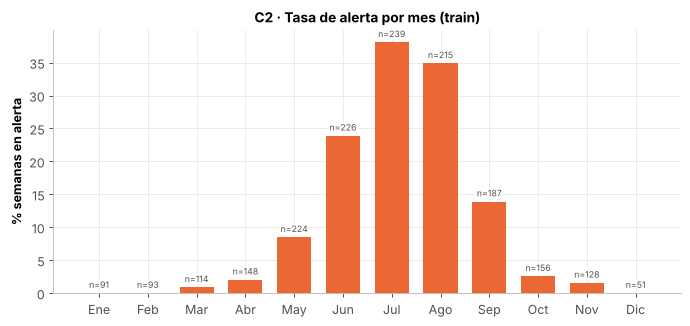

In [9]:
# ------------------------------------------------------------
# C2. Estacionalidad por MES (mediana y rango intercuartil)
# ------------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharex=True)
for ax, v in zip(axes.ravel(), fisicas):
    med = train.groupby("mes")[v].median()
    q1 = train.groupby("mes")[v].quantile(0.25)
    q3 = train.groupby("mes")[v].quantile(0.75)
    ax.fill_between(med.index, q1, q3, color=AZUL, alpha=0.2, linewidth=0)
    ax.plot(med.index, med.values, color=AZUL, lw=2, marker="o", ms=5)
    ax.set_title(v)
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels([m[0] for m in MESES], rotation=0)
fig.suptitle("C2 · Ciclo anual de las variables físicas (train · mediana y RIC)", fontweight="bold")
fig.tight_layout()
guardar(fig, "C2_estacionalidad_fisicas_mes")

tasa_mes = train_dino.groupby("mes")["alerta"].mean() * 100
n_mes = train_dino.groupby("mes")["alerta"].size()
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(tasa_mes.index, tasa_mes.values, color=NARANJO, width=0.7)
for m in tasa_mes.index:
    ax.text(m, tasa_mes[m] + 0.8, f"n={n_mes[m]}", ha="center", fontsize=7,
            color=TINTA_2, path_effects=BORDE)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(MESES, rotation=0)
ax.set_ylabel("% semanas en alerta")
ax.set_title("C2 · Tasa de alerta por mes (train)")
guardar(fig, "C2_tasa_alerta_mes")
NUMEROS["tasa_alerta_mes"] = {MESES[m - 1]: float(round(t, 1)) for m, t in tasa_mes.items()}

## D. Variables candidatas (*feature engineering*)

Todas miran **solo hacia atrás** en el tiempo (no usan información futura).
La climatología para las anomalías se calcula **solo con años de train**.

In [10]:
# ------------------------------------------------------------
# D0. Construcción de las variables candidatas
# ------------------------------------------------------------
# Estratificación
df["dT"] = df["sur_temp"] - df["bot_temp"]
df["dS"] = df["sur_salt"] - df["bot_salt"]

# Calendario circular (día del año evita el problema de la semana 53)
doy = df["time"].dt.dayofyear
df["sem_sin"] = np.sin(2 * np.pi * doy / 365.25)
df["sem_cos"] = np.cos(2 * np.pi * doy / 365.25)

base = fisicas + ["dT", "dS"]
g = df.groupby("ID")

for v in base:
    df[v + "_lag1"] = g[v].shift(1)
    df[v + "_lag2"] = g[v].shift(2)
    df[v + "_mm4"] = g[v].transform(lambda s: s.rolling(4, min_periods=4).mean())
    df[v + "_tend"] = df[v] - df[v + "_lag1"]          # cambio respecto a la semana previa

# Anomalías: valor - promedio de esa semana del año en esa bahía (climatología de train)
df["sem_clim"] = df["semana"].clip(upper=52)
clim = (df[df["año"] <= 2010]
        .groupby(["Group", "sem_clim"])[base].mean()
        .add_suffix("_clim")
        .reset_index())
df = df.merge(clim, on=["Group", "sem_clim"], how="left")
for v in base:
    df[v + "_anom"] = df[v] - df[v + "_clim"]
df = df.drop(columns=[v + "_clim" for v in base])
df = df.sort_values(["ID", "time"]).reset_index(drop=True)
g = df.groupby("ID")

# Escenario B: información biológica previa
df["D_lag1_log"] = np.log1p(g["D_total"].shift(1))
df["alerta_lag1"] = g["alerta"].shift(1)
# Último conteo disponible en las 4 semanas previas (rellena huecos de muestreo)
df["D_ult4_log"] = np.log1p(g["D_total"].transform(lambda s: s.shift(1).ffill(limit=3)))

# Diccionario de familias
familia = {}
for v in fisicas:
    familia[v] = "Original"
familia["dT"] = "Estratificación"
familia["dS"] = "Estratificación"
familia["sem_sin"] = "Calendario"
familia["sem_cos"] = "Calendario"
familia["lat"] = "Espacial"
familia["lon"] = "Espacial"
for v in base:
    familia[v + "_lag1"] = "Rezago"
    familia[v + "_lag2"] = "Rezago"
    familia[v + "_mm4"] = "Media móvil 4 sem"
    familia[v + "_tend"] = "Tendencia"
    familia[v + "_anom"] = "Anomalía"
familia["D_lag1_log"] = "Biológica (Esc. B)"
familia["D_ult4_log"] = "Biológica (Esc. B)"

candidatas = list(familia.keys())
print("N° de variables candidatas:", len(candidatas))
NUMEROS["n_candidatas"] = len(candidatas)

# Subconjunto de train con objetivo, ya con las variables nuevas
tr = df[(df["año"] <= 2010) & df["D_total"].notna()].copy()
assert len(tr) == len(train_dino)

N° de variables candidatas: 54


         variable             familia  pct_faltante    AUC  fuerza        direccion  AUC_verano  fuerza_verano  info_mutua
0      D_lag1_log  Biológica (Esc. B)          43.0  0.834   0.834  ↑ alto = alerta       0.783          0.783      0.1334
1          dT_mm4   Media móvil 4 sem           0.8  0.824   0.824  ↑ alto = alerta       0.670          0.670      0.1099
2      D_ult4_log  Biológica (Esc. B)          14.6  0.824   0.824  ↑ alto = alerta       0.774          0.774      0.1088
3         dT_lag1              Rezago           0.7  0.810   0.810  ↑ alto = alerta       0.661          0.661      0.0767
4              dT     Estratificación           0.6  0.800   0.800  ↑ alto = alerta       0.640          0.640      0.0747
5         dT_lag2              Rezago           0.7  0.800   0.800  ↑ alto = alerta       0.639          0.639      0.0774
6         PED_mm4   Media móvil 4 sem           0.8  0.783   0.783  ↑ alto = alerta       0.668          0.668      0.0739
7         sem_co

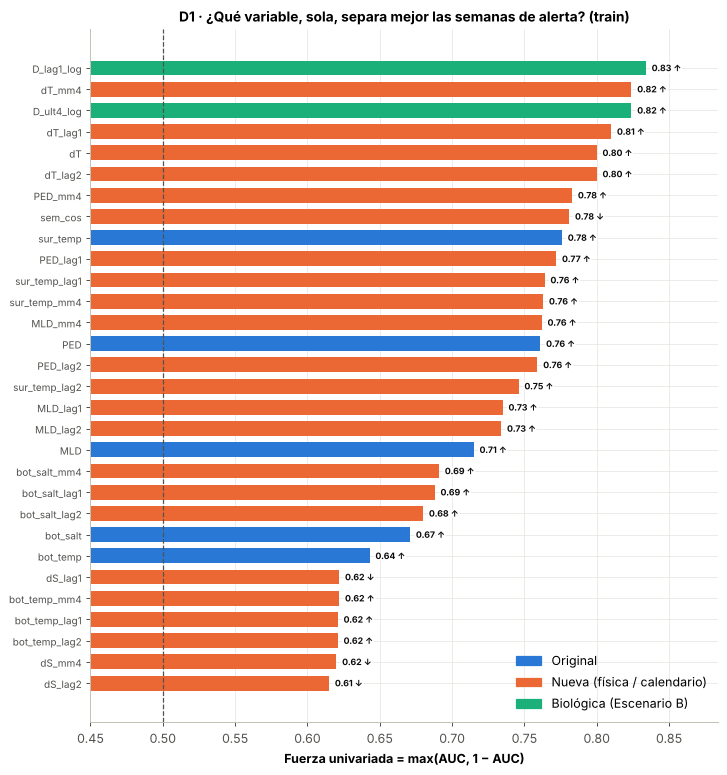

In [11]:
# ------------------------------------------------------------
# D1. Ranking univariado: AUC (todo el año), AUC (Jun–Sep) e información mutua
# ------------------------------------------------------------
verano = tr["mes"].between(6, 9)
filas = []
for v in candidatas:
    auc = auc_univariada(tr[v], tr["alerta"])
    auc_v = auc_univariada(tr.loc[verano, v], tr.loc[verano, "alerta"])
    m = tr[v].notna()
    mi = mutual_info_classif(tr.loc[m, [v]], tr.loc[m, "alerta"].astype(int),
                             discrete_features=False, n_neighbors=3, random_state=0)[0]
    filas.append({
        "variable": v,
        "familia": familia[v],
        "pct_faltante": round(tr[v].isna().mean() * 100, 1),
        "AUC": round(auc, 3),
        "fuerza": round(max(auc, 1 - auc), 3),          # 0,5 = no separa; 1 = separa perfecto
        "direccion": "↑ alto = alerta" if auc >= 0.5 else "↓ bajo = alerta",
        "AUC_verano": round(auc_v, 3) if not np.isnan(auc_v) else np.nan,
        "fuerza_verano": round(max(auc_v, 1 - auc_v), 3) if not np.isnan(auc_v) else np.nan,
        "info_mutua": round(mi, 4),
    })
ranking = pd.DataFrame(filas).sort_values("fuerza", ascending=False).reset_index(drop=True)
ranking.to_csv(os.path.join(CARPETA_TAB, "D1_ranking_univariado.csv"), index=False)
print(ranking.head(25).to_string())

# Gráfico: 30 mejores por fuerza (todo el año)
top = ranking.head(30).iloc[::-1]
col = []
for f in top["familia"]:
    if f == "Original":
        col.append(AZUL)
    elif f == "Biológica (Esc. B)":
        col.append(AQUA)
    else:
        col.append(NARANJO)
fig, ax = plt.subplots(figsize=(9, 10))
ax.barh(range(len(top)), top["fuerza"], color=col, height=0.7)
ax.set_yticks(range(len(top)))
ax.set_yticklabels(top["variable"], fontsize=8)
ax.axvline(0.5, color=TINTA_2, lw=1, ls="--")
ax.set_xlim(0.45, max(0.8, top["fuerza"].max() + 0.05))
for i, (f, d) in enumerate(zip(top["fuerza"], top["direccion"])):
    ax.text(f + 0.004, i, f"{f:.2f} {d[0]}", va="center", fontsize=7, fontweight="bold",
            color=TINTA, path_effects=BORDE)
ax.set_xlabel("Fuerza univariada = max(AUC, 1 − AUC)")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=AZUL, label="Original"),
                   Patch(color=NARANJO, label="Nueva (física / calendario)"),
                   Patch(color=AQUA, label="Biológica (Escenario B)")], loc="lower right")
ax.set_title("D1 · ¿Qué variable, sola, separa mejor las semanas de alerta? (train)")
guardar(fig, "D1_ranking_univariado")

                sur_temp  bot_temp  sur_salt  ...    MLD     dT     dS
rezago_semanas                                ...                     
0                  0.776     0.643     0.584  ...  0.715  0.800  0.385
1                  0.764     0.621     0.595  ...  0.735  0.810  0.378
2                  0.746     0.621     0.591  ...  0.734  0.800  0.385
3                  0.724     0.602     0.583  ...  0.736  0.795  0.378
4                  0.710     0.589     0.574  ...  0.715  0.780  0.395
5                  0.688     0.578     0.569  ...  0.706  0.773  0.419
6                  0.662     0.580     0.548  ...  0.666  0.743  0.426
7                  0.632     0.569     0.525  ...  0.642  0.713  0.410
8                  0.608     0.549     0.514  ...  0.637  0.701  0.423

[9 rows x 8 columns]


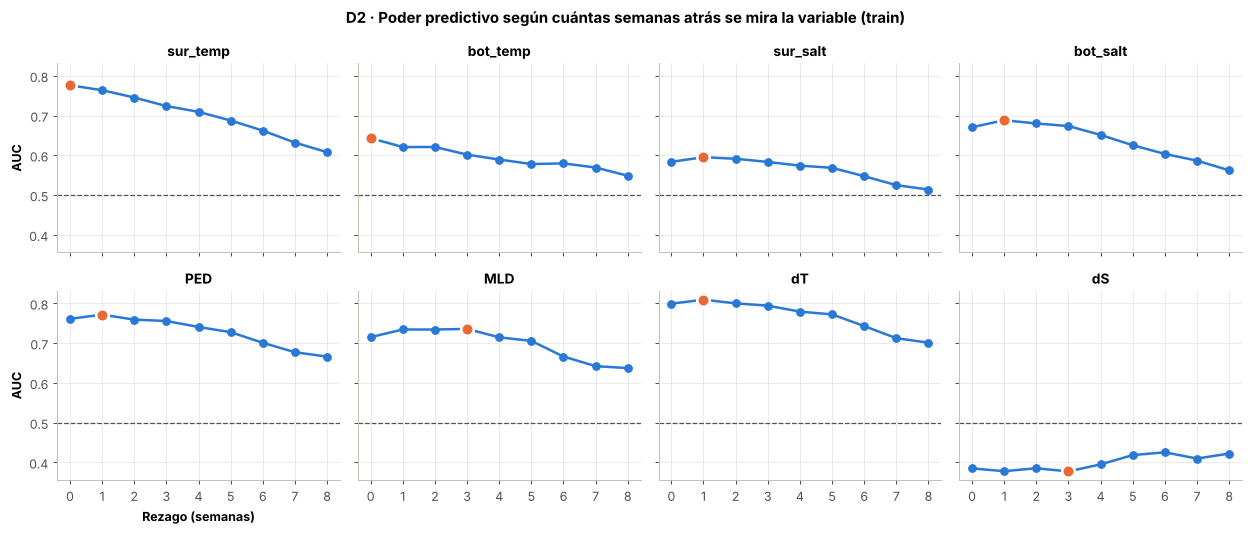

In [12]:
# ------------------------------------------------------------
# D2. ¿Cuántas semanas de rezago sirven? AUC según el rezago (0 a 8 semanas)
# ------------------------------------------------------------
rezagos = list(range(0, 9))
tabla_rez = pd.DataFrame(index=rezagos, columns=base, dtype=float)
for v in base:
    for k in rezagos:
        serie = g[v].shift(k)
        x = serie[(df["año"] <= 2010) & df["D_total"].notna()]
        tabla_rez.loc[k, v] = auc_univariada(x, tr["alerta"])
tabla_rez.index.name = "rezago_semanas"
tabla_rez.round(3).to_csv(os.path.join(CARPETA_TAB, "D2_auc_por_rezago.csv"))
print(tabla_rez.round(3))

fig, axes = plt.subplots(2, 4, figsize=(14, 6), sharex=True, sharey=True)
for ax, v in zip(axes.ravel(), base):
    ax.plot(rezagos, tabla_rez[v], color=AZUL, lw=2, marker="o", ms=6)
    ax.axhline(0.5, color=TINTA_2, lw=1, ls="--")
    k_mejor = (tabla_rez[v] - 0.5).abs().idxmax()
    ax.plot(k_mejor, tabla_rez.loc[k_mejor, v], "o", ms=10, color=NARANJO,
            markeredgecolor="white", markeredgewidth=2)
    ax.set_title(v)
    ax.set_xticks(rezagos)
axes[1, 0].set_xlabel("Rezago (semanas)")
axes[0, 0].set_ylabel("AUC")
axes[1, 0].set_ylabel("AUC")
fig.suptitle("D2 · Poder predictivo según cuántas semanas atrás se mira la variable (train)",
             fontweight="bold")
fig.tight_layout()
guardar(fig, "D2_auc_por_rezago")

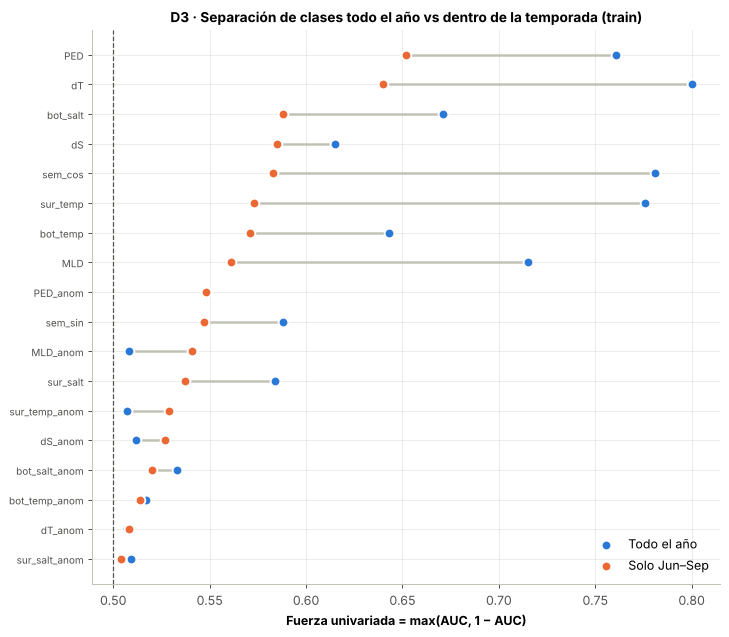

In [13]:
# ------------------------------------------------------------
# D3. ¿Aporta la física más allá de la estación? Todo el año vs solo Jun–Sep
# ------------------------------------------------------------
comp = ranking[ranking["familia"].isin(["Original", "Estratificación", "Anomalía", "Calendario"])].copy()
comp = comp.sort_values("fuerza_verano", ascending=True)
NUMEROS["prevalencia_verano"] = float(round(tr.loc[verano, "alerta"].mean() * 100, 1))
NUMEROS["n_verano"] = int(verano.sum())

fig, ax = plt.subplots(figsize=(9, 8))
yy = np.arange(len(comp))
for i, (a, b) in enumerate(zip(comp["fuerza"], comp["fuerza_verano"])):
    ax.plot([a, b], [i, i], color="#c3c2b7", lw=2, zorder=1)
ax.scatter(comp["fuerza"], yy, s=60, color=AZUL, label="Todo el año", zorder=2,
           edgecolor="white", linewidth=1.5)
ax.scatter(comp["fuerza_verano"], yy, s=60, color=NARANJO, label="Solo Jun–Sep", zorder=3,
           edgecolor="white", linewidth=1.5)
ax.set_yticks(yy)
ax.set_yticklabels(comp["variable"], fontsize=8)
ax.axvline(0.5, color=TINTA_2, lw=1, ls="--")
ax.set_xlabel("Fuerza univariada = max(AUC, 1 − AUC)")
ax.legend(loc="lower right")
ax.set_title("D3 · Separación de clases todo el año vs dentro de la temporada (train)")
guardar(fig, "D3_todo_año_vs_verano")

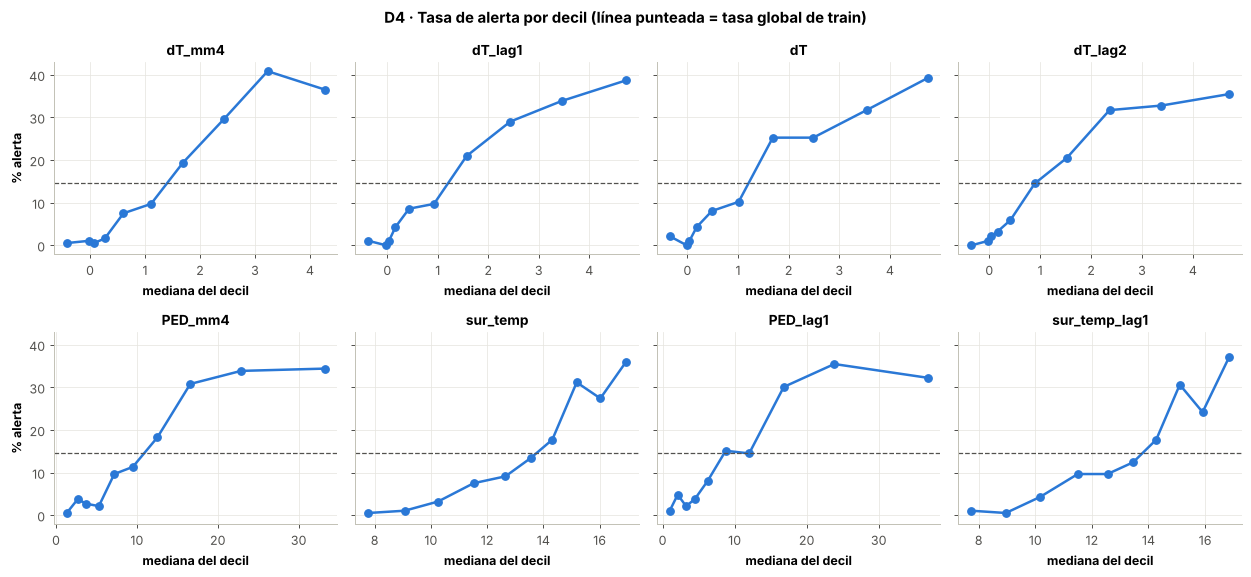

In [14]:
# ------------------------------------------------------------
# D4. Forma de la relación: % de alerta por decil de cada variable
# ------------------------------------------------------------
fisicas_rank = ranking[~ranking["familia"].isin(["Biológica (Esc. B)", "Calendario", "Espacial"])]
top8 = fisicas_rank["variable"].head(8).tolist()
NUMEROS["top8_fisicas"] = top8

fig, axes = plt.subplots(2, 4, figsize=(14, 6.5), sharey=True)
tablas_dec = []
for ax, v in zip(axes.ravel(), top8):
    d = tr[[v, "alerta"]].dropna().copy()
    d["decil"] = pd.qcut(d[v], 10, duplicates="drop")
    res = d.groupby("decil", observed=True).agg(x=(v, "median"), tasa=("alerta", "mean"), n=("alerta", "size"))
    res["variable"] = v
    tablas_dec.append(res.reset_index(drop=True))
    ax.plot(res["x"], res["tasa"] * 100, color=AZUL, lw=2, marker="o", ms=6)
    ax.axhline(tr["alerta"].mean() * 100, color=TINTA_2, lw=1, ls="--")
    ax.set_title(v)
    ax.set_xlabel("mediana del decil")
axes[0, 0].set_ylabel("% alerta")
axes[1, 0].set_ylabel("% alerta")
fig.suptitle("D4 · Tasa de alerta por decil (línea punteada = tasa global de train)",
             fontweight="bold")
fig.tight_layout()
guardar(fig, "D4_alerta_por_decil")
pd.concat(tablas_dec).to_csv(os.path.join(CARPETA_TAB, "D4_alerta_por_decil.csv"), index=False)

Pares con |rho| > 0,9: 21
            var_1          var_2    rho
8   sur_temp_lag1   sur_temp_mm4  0.981
9   sur_temp_lag2   sur_temp_mm4  0.980
16  bot_salt_lag2   bot_salt_mm4  0.960
15  bot_salt_lag1   bot_salt_mm4  0.959
10  bot_temp_lag1   bot_temp_mm4  0.952
1        sur_temp   sur_temp_mm4  0.951
11  bot_temp_lag2   bot_temp_mm4  0.951
7   sur_temp_lag1  sur_temp_lag2  0.950
0        sur_temp  sur_temp_lag1  0.947
20        dT_lag2         dT_mm4  0.937
19        dT_lag1         dT_mm4  0.936
12  sur_salt_lag1   sur_salt_mm4  0.935
18       PED_lag2        PED_mm4  0.935
13  sur_salt_lag2   sur_salt_mm4  0.932
17       PED_lag1        PED_mm4  0.931
5             PED        PED_mm4  0.909
4        bot_salt   bot_salt_mm4  0.908
6              dT         dT_mm4  0.905
2        bot_temp   bot_temp_mm4  0.905
3        bot_salt  bot_salt_lag1  0.902
14  bot_salt_lag1  bot_salt_lag2  0.901


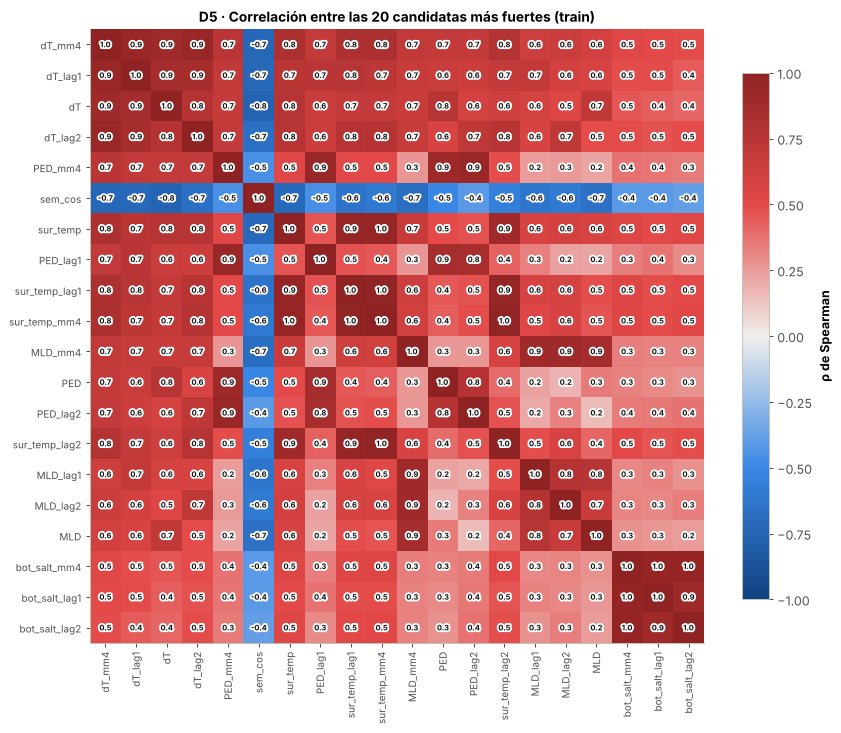

In [15]:
# ------------------------------------------------------------
# D5. Redundancia: Spearman entre candidatas y pares con |ρ| > 0,9
# ------------------------------------------------------------
no_bio = [v for v in candidatas if familia[v] != "Biológica (Esc. B)"]
rho = tr[no_bio].corr(method="spearman")

pares = []
for i in range(len(no_bio)):
    for j in range(i + 1, len(no_bio)):
        r = rho.iat[i, j]
        if abs(r) > 0.9:
            pares.append({"var_1": no_bio[i], "var_2": no_bio[j], "rho": round(r, 3)})
pares = pd.DataFrame(pares, columns=["var_1", "var_2", "rho"]).sort_values("rho", key=abs, ascending=False)
pares.to_csv(os.path.join(CARPETA_TAB, "D5_pares_redundantes.csv"), index=False)
print("Pares con |rho| > 0,9:", len(pares))
print(pares.head(30).to_string())
NUMEROS["n_pares_redundantes"] = int(len(pares))

# Filtro de redundancia: recorre el ranking y descarta la que choca con una mejor
orden = [v for v in ranking["variable"] if v in no_bio]
seleccion = []
redundante_con = {}
for v in orden:
    choque = None
    for s in seleccion:
        if abs(rho.loc[v, s]) > 0.9:
            choque = s
            break
    if choque is None:
        seleccion.append(v)
    else:
        redundante_con[v] = choque
NUMEROS["n_tras_filtro_redundancia"] = len(seleccion)

# Mapa de calor de las 20 mejores (sin biológicas)
top20 = orden[:20]
r20 = rho.loc[top20, top20]
fig, ax = plt.subplots(figsize=(11, 9.5))
im = ax.imshow(r20.values, cmap=CMAP_DIV, vmin=-1, vmax=1)
ax.set_xticks(range(len(top20)))
ax.set_xticklabels(top20, rotation=90, fontsize=8)
ax.set_yticks(range(len(top20)))
ax.set_yticklabels(top20, fontsize=8)
ax.grid(False)
for i in range(len(top20)):
    for j in range(len(top20)):
        ax.text(j, i, f"{r20.iat[i, j]:.1f}", ha="center", va="center", fontsize=6,
                fontweight="bold", color=TINTA, path_effects=BORDE)
plt.colorbar(im, ax=ax, label="ρ de Spearman", shrink=0.8)
ax.set_title("D5 · Correlación entre las 20 candidatas más fuertes (train)")
guardar(fig, "D5_redundancia_spearman")

P(alerta | previa en alerta)   = 62.0%  (n=187)
P(alerta | previa sin alerta)  = 8.8%  (n=880)
Disponibilidad lag1: 57.0% | último conteo ≤4 sem: 85.4%


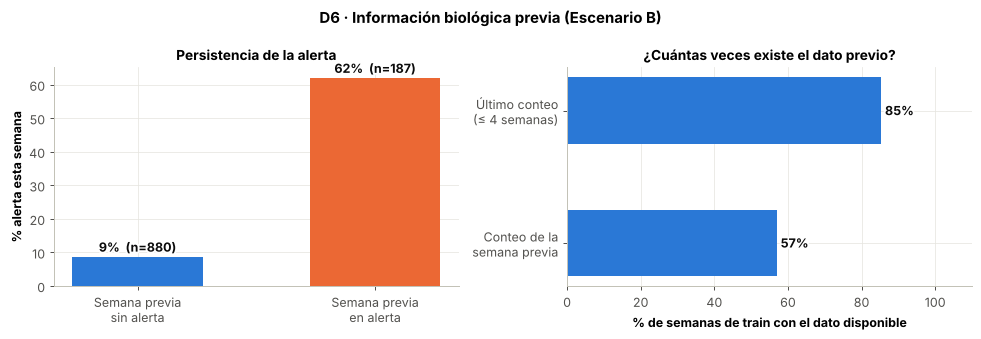

In [16]:
# ------------------------------------------------------------
# D6. Persistencia (Escenario B): ¿la alerta de la semana previa anticipa la actual?
# ------------------------------------------------------------
pers = tr[["alerta", "alerta_lag1"]].dropna()
p_si = pers.loc[pers["alerta_lag1"] == 1, "alerta"].mean() * 100
p_no = pers.loc[pers["alerta_lag1"] == 0, "alerta"].mean() * 100
n_si = int((pers["alerta_lag1"] == 1).sum())
n_no = int((pers["alerta_lag1"] == 0).sum())
disp_lag1 = tr["D_lag1_log"].notna().mean() * 100
disp_ult4 = tr["D_ult4_log"].notna().mean() * 100
print(f"P(alerta | previa en alerta)   = {p_si:.1f}%  (n={n_si})")
print(f"P(alerta | previa sin alerta)  = {p_no:.1f}%  (n={n_no})")
print(f"Disponibilidad lag1: {disp_lag1:.1f}% | último conteo ≤4 sem: {disp_ult4:.1f}%")
NUMEROS.update({"p_alerta_si_previa": round(p_si, 1), "p_alerta_no_previa": round(p_no, 1),
                "n_previa_si": n_si, "n_previa_no": n_no,
                "disp_lag1": round(disp_lag1, 1), "disp_ult4": round(disp_ult4, 1)})

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].bar(["Semana previa\nsin alerta", "Semana previa\nen alerta"], [p_no, p_si],
            color=[AZUL, NARANJO], width=0.55)
for i, (p, n) in enumerate([(p_no, n_no), (p_si, n_si)]):
    axes[0].text(i, p + 1.5, f"{p:.0f}%  (n={n})", ha="center", fontweight="bold",
                 color=TINTA, path_effects=BORDE)
axes[0].set_ylabel("% alerta esta semana")
axes[0].set_title("Persistencia de la alerta")
axes[0].tick_params(axis="x", rotation=0)
axes[1].barh(["Conteo de la\nsemana previa", "Último conteo\n(≤ 4 semanas)"],
             [disp_lag1, disp_ult4], color=AZUL, height=0.5)
for i, p in enumerate([disp_lag1, disp_ult4]):
    axes[1].text(p + 1, i, f"{p:.0f}%", va="center", fontweight="bold", color=TINTA, path_effects=BORDE)
axes[1].set_xlim(0, 110)
axes[1].set_xlabel("% de semanas de train con el dato disponible")
axes[1].set_title("¿Cuántas veces existe el dato previo?")
fig.suptitle("D6 · Información biológica previa (Escenario B)", fontweight="bold")
fig.tight_layout()
guardar(fig, "D6_persistencia")

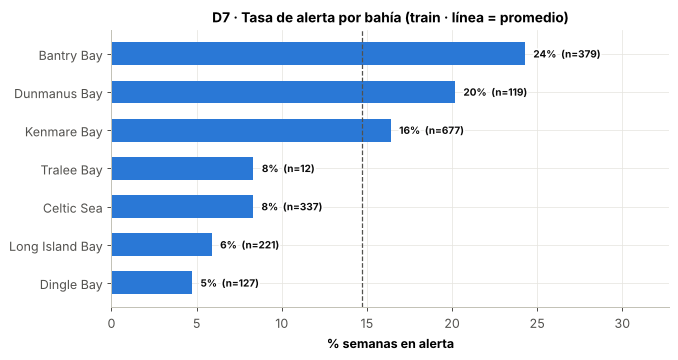

In [17]:
# ------------------------------------------------------------
# D7. Efecto de la bahía
# ------------------------------------------------------------
bahia = tr.groupby("Group").agg(n=("alerta", "size"), tasa=("alerta", "mean")).sort_values("tasa")
bahia.to_csv(os.path.join(CARPETA_TAB, "D7_alerta_por_bahia.csv"))
NUMEROS["tasa_bahia"] = {k: float(round(v * 100, 1)) for k, v in bahia["tasa"].items()}
NUMEROS["n_bahia"] = {k: int(v) for k, v in bahia["n"].items()}

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(bahia.index, bahia["tasa"] * 100, color=AZUL, height=0.6)
for i, (t, n) in enumerate(zip(bahia["tasa"], bahia["n"])):
    ax.text(t * 100 + 0.5, i, f"{t*100:.0f}%  (n={n})", va="center", fontsize=8,
            fontweight="bold", color=TINTA, path_effects=BORDE)
ax.axvline(tr["alerta"].mean() * 100, color=TINTA_2, lw=1, ls="--")
ax.set_xlim(0, bahia["tasa"].max() * 100 * 1.35)
ax.set_xlabel("% semanas en alerta")
ax.set_title("D7 · Tasa de alerta por bahía (train · línea = promedio)")
guardar(fig, "D7_alerta_por_bahia")

## E. Tabla resumen y recomendaciones automáticas

In [18]:
resumen = ranking.copy()
resumen["redundante_con"] = resumen["variable"].map(redundante_con)
recom = []
for _, r in resumen.iterrows():
    if r["familia"] == "Biológica (Esc. B)":
        recom.append("Solo Escenario B")
    elif isinstance(r["redundante_con"], str):
        recom.append("Descartar (redundante con " + r["redundante_con"] + ")")
    elif r["pct_faltante"] > 30:
        recom.append("Revisar: muchos faltantes")
    elif r["fuerza"] >= 0.65 or (not np.isnan(r["fuerza_verano"]) and r["fuerza_verano"] >= 0.60):
        recom.append("Incluir (fuerte)")
    elif r["fuerza"] >= 0.55:
        recom.append("Incluir (moderada)")
    else:
        recom.append("Débil: probar en selección")
resumen["recomendacion"] = recom
resumen.to_csv(os.path.join(CARPETA_TAB, "E_resumen_feature_engineering.csv"), index=False)
print(resumen[["variable", "familia", "fuerza", "fuerza_verano", "info_mutua",
               "pct_faltante", "recomendacion"]].to_string())

NUMEROS["conteo_recomendaciones"] = resumen["recomendacion"].str.split(" \\(").str[0].value_counts().to_dict()
NUMEROS["top10"] = resumen.head(10)[["variable", "familia", "fuerza", "fuerza_verano",
                                     "info_mutua", "direccion", "recomendacion"]].to_dict(orient="records")
NUMEROS["top10_verano"] = (resumen.dropna(subset=["fuerza_verano"])
                           .sort_values("fuerza_verano", ascending=False)
                           .head(10)[["variable", "familia", "fuerza", "fuerza_verano"]]
                           .to_dict(orient="records"))

with open(os.path.join(CARPETA, "resumen_numeros.json"), "w", encoding="utf-8") as f:
    json.dump(NUMEROS, f, ensure_ascii=False, indent=2, default=str)
print("\nListo. Figuras en", CARPETA_FIG, "| tablas en", CARPETA_TAB)

         variable             familia  fuerza  fuerza_verano  info_mutua  pct_faltante                            recomendacion
0      D_lag1_log  Biológica (Esc. B)   0.834          0.783      0.1334          43.0                         Solo Escenario B
1          dT_mm4   Media móvil 4 sem   0.824          0.670      0.1099           0.8                         Incluir (fuerte)
2      D_ult4_log  Biológica (Esc. B)   0.824          0.774      0.1088          14.6                         Solo Escenario B
3         dT_lag1              Rezago   0.810          0.661      0.0767           0.7        Descartar (redundante con dT_mm4)
4              dT     Estratificación   0.800          0.640      0.0747           0.6        Descartar (redundante con dT_mm4)
5         dT_lag2              Rezago   0.800          0.639      0.0774           0.7        Descartar (redundante con dT_mm4)
6         PED_mm4   Media móvil 4 sem   0.783          0.668      0.0739           0.8                  